In [1]:
import numpy as np
import jax
import jax.numpy as jnp
import pypesto
from pypesto.result import OptimizerResult
import pypesto.profile as profile
from cmfa.functions import ordered_ilr_func, calculate_ci

import sys
sys.path.insert(0, "../scripts")
import toy_network
import tca_cycle

import pickle
from pathlib import Path

from functools import partial

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.lines import Line2D
import matplotlib.patches as mpatches
from matplotlib.colors import to_rgba

from jax import config

config.update("jax_enable_x64", True)

import scipy.stats as stats
import optimistix

SEED = 1234
key = jax.random.key(seed=SEED)
key_toy, key = jax.random.split(key)
key_tca, key = jax.random.split(key)
RESULTS_DIR_TOY = Path("..") / "data" / "results" / "toy_example"
RESULTS_DIR_TCA = Path("..") / "data" / "results" / "tca_cycle"
PLOT_DIR = Path("..") / "figures"
# ── palette ───────────────────────────────────────────────────────────────────
CRIMSON = '#73102A'   # P point
INDIGO  = '#1C0B9C'   # Q point
OLIVE   = '#558C03'   # simplex face
TEAL    = '#038C7F'   # vertices
DIST_E  = "#DB7211"   # Euclidean distance (amber/gold)
DIST_A  = '#9C27B0'   # Aitchison distance (purple)

# Axis colors
A_COLOR = '#CC4400'   # Axis A (deep orange-red)
B_COLOR = '#007700'   # Axis B (forest green)
C_COLOR = '#0044BB'   # Axis C (medium blue)

TRAD  = "#DB7211" 
ILR =  '#038C7F'

combined = "#8CAA8D"

IDX_TOY = 4699
IDX_TCA = 5741

def fisher_interval(log_flux_est, flux_sd, xlim=None):
    mu = log_flux_est
    sigma = flux_sd
    if xlim is not None:
        # Sample directly over the display window (in flux space) rather than
        # mu +/- 2.4*sigma in log space: when sigma is huge (near-unidentifiable
        # parameters), exponentiating the log-space grid overflows/underflows
        # float64 and the curve vanishes from the visible axis entirely.
        eps = 1e-300
        x_axis = np.log(np.linspace(max(xlim[0], eps), xlim[1], 500))
    else:
        x_start = (mu - 2.4 * sigma)
        x_end = (mu + 2.4 * sigma)
        x_axis = np.linspace(x_start, x_end, 500)

    # Calculate Log-Normal PDF
    y_raw = stats.norm.pdf(x_axis, mu, sigma)

    return np.exp(x_axis), y_raw

In [2]:
# Toy network
true_mid_toy = np.load(RESULTS_DIR_TOY / "true_composition.npy")
true_flux_toy = np.load(RESULTS_DIR_TOY / "true_flux.npy")
simulated_mid_toy = jnp.load(RESULTS_DIR_TOY / "id_simulated_reference.npy")

with open(RESULTS_DIR_TOY / "estimated_fluxes_reference.pkl", "rb") as f:
    estimated_fluxes_toy = pickle.load(f)

random_sim_toy = simulated_mid_toy[IDX_TOY]

sd_trad_toy = np.std(simulated_mid_toy, axis=0)
sd_ilr_toy = np.std(ordered_ilr_func(simulated_mid_toy), axis=0)

weights_trad_toy = 1/sd_trad_toy
weights_ilr_toy = 1/sd_ilr_toy

# 2. Optimization with Optimistix
# Note: Ensure loss_trad signature is: loss_trad(params, args)
init_guess_toy = jnp.array([100.0, 50.0])
solver = optimistix.BFGS(rtol=1e-8, atol=1e-8)

opt_result_trad_toy = optimistix.minimise(
    toy_network.loss_trad,
    y0=jnp.log(init_guess_toy),
    args=(random_sim_toy, weights_trad_toy),
    solver=solver,
    max_steps=10000,
    throw=False,
    has_aux=True,
)

opt_result_ilr_toy = optimistix.minimise(
    toy_network.loss_ilr,
    y0=jnp.log(init_guess_toy),
    args=(random_sim_toy, weights_ilr_toy),
    solver=solver,
    max_steps=10000,
    throw=False,
    has_aux=True,
)

est_trad_toy = estimated_fluxes_toy["trad"][:, [4, 5]]
est_ilr_toy = estimated_fluxes_toy["ilr"][:, [4, 5]]

inv_hessian_trad_toy = opt_result_trad_toy.state.f_info.hessian_inv.pytree
standard_errors_trad_toy = jnp.sqrt(jnp.diag(inv_hessian_trad_toy))

inv_hessian_ilr_toy = opt_result_ilr_toy.state.f_info.hessian_inv.pytree
standard_errors_ilr_toy = jnp.sqrt(jnp.diag(inv_hessian_ilr_toy))


In [3]:
# tca cycle
true_mid_tca = np.load(RESULTS_DIR_TCA / "true_composition.npy", allow_pickle=True).item()
true_flux_tca = np.load(RESULTS_DIR_TCA / "true_flux.npy", allow_pickle=True)
simulated_mid_tca = jnp.load(RESULTS_DIR_TCA / "id_simulated_reference.pkl", allow_pickle=True)

with open(RESULTS_DIR_TCA / "estimated_fluxes_reference.pkl", "rb") as f:
    estimated_fluxes_tca = pickle.load(f)

random_sim_tca = jax.tree.map(lambda x: x[IDX_TCA], simulated_mid_tca)

sd_trad_tca = jax.tree.map(lambda x: np.std(x, axis=0), simulated_mid_tca)
sd_ilr_tca = jax.tree.map(lambda x: np.std(ordered_ilr_func(x), axis=0), simulated_mid_tca)

weights_trad_tca = jax.tree.map(lambda s: 1/s, sd_trad_tca)
weights_ilr_tca = jax.tree.map(lambda s: 1/s, sd_ilr_tca)

init_guess_tca = np.array([0.2, 0.2, 0.2])
solver = optimistix.BFGS(rtol=1e-8, atol=1e-8)

opt_result_trad_tca = optimistix.minimise(
    tca_cycle.loss_trad,
    y0=jnp.log(init_guess_tca),
    args=(random_sim_tca, weights_trad_tca),
    solver=solver,
    max_steps=10000,
    throw=False,
    has_aux=True,
)

opt_result_ilr_tca = optimistix.minimise(
    tca_cycle.loss_ilr,
    y0=jnp.log(init_guess_tca),
    args=(random_sim_tca, weights_ilr_tca),
    solver=solver,
    max_steps=10000,
    throw=False,
    has_aux=True,
)

est_trad_tca = estimated_fluxes_tca["trad"]
est_ilr_tca = estimated_fluxes_tca["ilr"]

inv_hessian_trad_tca = opt_result_trad_tca.state.f_info.hessian_inv.pytree
standard_errors_trad_tca = jnp.sqrt(jnp.diag(inv_hessian_trad_tca))

inv_hessian_ilr_tca = opt_result_ilr_tca.state.f_info.hessian_inv.pytree
standard_errors_ilr_tca = jnp.sqrt(jnp.diag(inv_hessian_ilr_tca))

In [4]:
# est_trad_toy[:, 0], "est_i": est_ilr_toy[:, 0]
mc_toy_trad = np.array([[np.quantile(est_trad_toy[:, 0], 0.025), np.quantile(est_trad_toy[:, 0], 0.975)], 
                        [np.quantile(est_trad_toy[:, 1], 0.025), np.quantile(est_trad_toy[:, 1], 0.975)]])

mc_toy_ilr = np.array([[np.quantile(est_ilr_toy[:, 0], 0.025), np.quantile(est_ilr_toy[:, 0], 0.975)], 
                        [np.quantile(est_ilr_toy[:, 1], 0.025), np.quantile(est_ilr_toy[:, 1], 0.975)]])

mc_tca_trad = np.array([[np.quantile(est_trad_tca[:, 0], 0.025), np.quantile(est_trad_tca[:, 0], 0.975)], 
                        [np.quantile(est_trad_tca[:, 1], 0.025), np.quantile(est_trad_tca[:, 1], 0.975)],
                        [np.quantile(est_trad_tca[:, 2], 0.025), np.quantile(est_trad_tca[:, 2], 0.975)]])

mc_tca_ilr = np.array([[np.quantile(est_ilr_tca[:, 0], 0.025), np.quantile(est_ilr_tca[:, 0], 0.975)], 
                        [np.quantile(est_ilr_tca[:, 1], 0.025), np.quantile(est_ilr_tca[:, 1], 0.975)],
                        [np.quantile(est_ilr_tca[:, 2], 0.025), np.quantile(est_ilr_tca[:, 2], 0.975)]])

In [5]:
def get_sigma_v(N, inv_hessian, ix_input_flux):
    n_nofixed = jnp.delete(N, ix_input_flux, axis=1)
    # jax.debug.breakpoint()
    return n_nofixed @ inv_hessian @ n_nofixed.T

In [6]:
m_toy = jnp.array([[-1, -1, 2], [0, 0, -1], [-1, 0, 1]])
n_toy = jnp.vstack([-m_toy, jnp.eye(3)])
ix_input_flux_toy = np.array([0])

sigma_v_trad = get_sigma_v(n_toy, inv_hessian_trad_toy, ix_input_flux_toy)
v3_trad, v5_trad = jnp.exp(opt_result_trad_toy.value)

v_free_trad = jnp.array([100, v3_trad, v5_trad])
# The fluxes calcualted from M and the free fluxes
v_full_trad = n_toy @ v_free_trad

flux_ci_toy_trad = calculate_ci(sigma_v_trad, jnp.log(v_full_trad))
print(flux_ci_toy_trad)

[[1.43406914e-02 7.25306208e+05]
 [3.82530770e+00 1.10873796e+02]
 [1.47492606e+01 4.27496724e+02]
 [1.00000000e+02 1.00000000e+02]
 [3.14819460e-04 5.92135000e+06]
 [3.82530770e+00 1.10873796e+02]]


In [7]:
sigma_v_ilr = get_sigma_v(n_toy, inv_hessian_ilr_toy, ix_input_flux_toy)
v3_ilr, v5_ilr = jnp.exp(opt_result_ilr_toy.value)

v_free_ilr = jnp.array([100, v3_ilr, v5_ilr])
# The fluxes calcualted from M and the free fluxes
v_full_ilr = n_toy @ v_free_ilr

flux_ci_toy_ilr = calculate_ci(sigma_v_ilr, jnp.log(v_full_ilr))
print(flux_ci_toy_ilr)

[[ 21.34838035 594.6908955 ]
 [ 13.97798304  29.2632703 ]
 [ 55.13518887 115.42694899]
 [100.         100.        ]
 [ 20.50287923 137.6505528 ]
 [ 13.97798304  29.2632703 ]]


In [8]:
V_FREE = {"v8": 0.215, "v1": 1, "v19": 0.05, "v20": 0.03, "v16": 0.07, "v17": 0.23, "v18": 0.12, "v2": 0.201, "v9": 0.296}
KNOWN_KEYS = ["v1", "v16", "v17", "v18", "v19", "v20"]
KNOWN_FLUXES = {k: V_FREE[k] for k in KNOWN_KEYS}
FREE_KEYS = ["v8", "v2", "v9"]

flux_from_free = partial(
    tca_cycle.flux_vector,
    fixed=KNOWN_FLUXES,
)
n_tca = tca_cycle.get_N()
ix_input_flux_tca = np.array([1,2,3,4,5,6])

In [78]:
flux_est_trad = flux_from_free(jnp.exp(opt_result_trad_tca.value))
sigma_v_tca_trad = get_sigma_v(n_tca, inv_hessian_trad_tca, ix_input_flux_tca)
flux_est_jax = jnp.array([flux_est_trad[k] for k in flux_est_trad.keys()])
flux_ci_tca_trad = calculate_ci(sigma_v_tca_trad, jnp.log(flux_est_jax))

In [79]:
flux_est_ilr = flux_from_free(jnp.exp(opt_result_ilr_tca.value))
sigma_v_tca_ilr = get_sigma_v(n_tca, inv_hessian_ilr_tca, ix_input_flux_tca)
flux_est_jax_ilr = jnp.array([flux_est_ilr[k] for k in flux_est_ilr.keys()])
flux_ci_tca_ilr = calculate_ci(sigma_v_tca_ilr, jnp.log(flux_est_jax_ilr))

In [11]:
# reduction
for i in np.array([4, 5]):
    print(((flux_ci_toy_trad[i,1]-flux_ci_toy_trad[i,0]) - (flux_ci_toy_ilr[i,1]-flux_ci_toy_ilr[i,0]))/(flux_ci_toy_trad[i,1]-flux_ci_toy_trad[i,0]))

for i in np.array([0, 7, 8]):
    print(((flux_ci_tca_trad[i,1]-flux_ci_tca_trad[i,0]) - (flux_ci_tca_ilr[i,1]-flux_ci_tca_ilr[i,0]))/(flux_ci_tca_trad[i,1]-flux_ci_tca_trad[i,0]))

0.9999802160531782
0.8572115538272118
nan
0.7078312319639115
0.8898337502160639


In [12]:
np.mean(np.array([0.9999789570160221,
                0.856660455317294,
                0.9761211861278558,
                0.7863170530498749,
                0.9368913794559693]))

np.float64(0.9111938061934032)

## Profile likelihood

In [ ]:
with open(RESULTS_DIR_TOY / "profile_likelihood.pkl", "rb") as f:
    profile_toy = pickle.load(f)
with open(RESULTS_DIR_TCA / "profile_likelihood.pkl", "rb") as f:
    profile_tca = pickle.load(f)

profile_cis_toy_trad = profile_toy["trad"]["ci"]
profile_cis_toy_ilr = profile_toy["ilr"]["ci"]

profile_cis_tca_trad = profile_tca["trad"]["ci"]
profile_cis_tca_ilr = profile_tca["ilr"]["ci"]

## Combined comparison figure (3 methods x 5 fluxes)

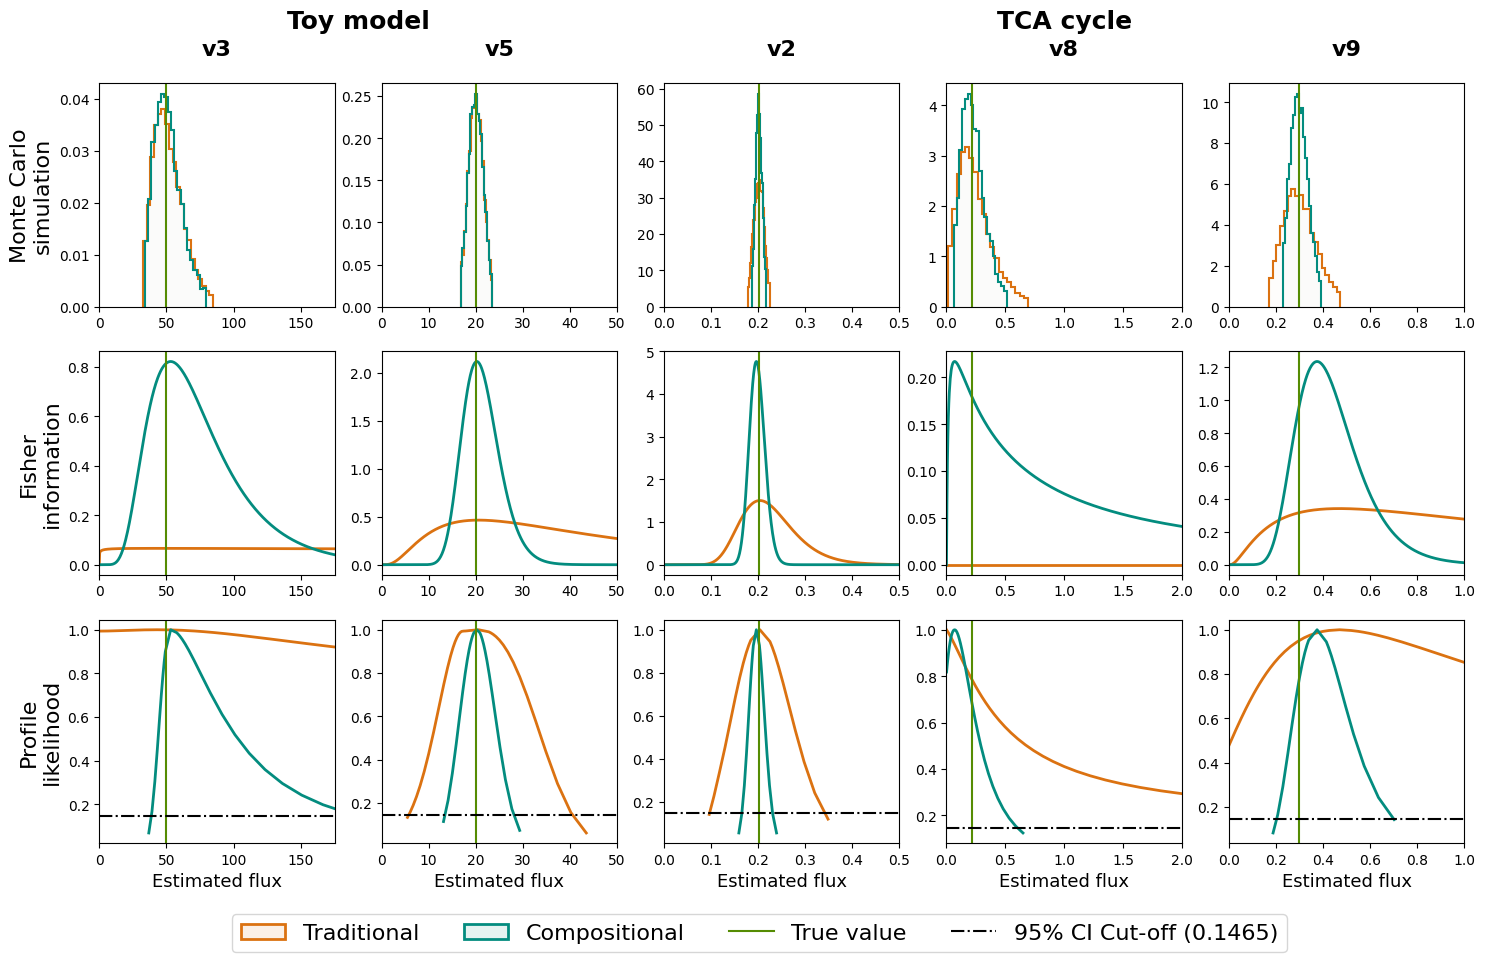

In [ ]:
# --- Figure & Layout Setup: 3 rows (methods) x 5 columns (fluxes) ---
f3 = plt.figure(figsize=(15, 10))
gs3 = gridspec.GridSpec(3, 5, left=0.06, right=0.97, top=0.86, bottom=0.10, hspace=0.2, wspace=0.2)
axes3 = [[plt.subplot(gs3[r, c]) for c in range(5)] for r in range(3)]

# --- Per-column configuration: one entry per flux, shared across all 3 rows ---
col_configs = [
    {"idx": 0, "true_value": true_flux_toy[2], "opt_t": opt_result_trad_toy, "opt_i": opt_result_ilr_toy,
     "se_t": standard_errors_trad_toy, "se_i": standard_errors_ilr_toy,
     "est_t": est_trad_toy[:, 0], "est_i": est_ilr_toy[:, 0],
     "res_t": profile_toy["trad"]["v3"], "res_i": profile_toy["ilr"]["v3"],
     "title": "v3", "xlim": (0, 175)},
    {"idx": 1, "true_value": true_flux_toy[4], "opt_t": opt_result_trad_toy, "opt_i": opt_result_ilr_toy,
     "se_t": standard_errors_trad_toy, "se_i": standard_errors_ilr_toy,
     "est_t": est_trad_toy[:, 1], "est_i": est_ilr_toy[:, 1],
     "res_t": profile_toy["trad"]["v5"], "res_i": profile_toy["ilr"]["v5"],
     "title": "v5", "xlim": (0, 50)},
    {"idx": 1, "true_value": true_flux_tca.item()["v2"], "opt_t": opt_result_trad_tca, "opt_i": opt_result_ilr_tca,
     "se_t": standard_errors_trad_tca, "se_i": standard_errors_ilr_tca,
     "est_t": est_trad_tca[:, 1], "est_i": est_ilr_tca[:, 1],
     "res_t": profile_tca["trad"]["v2"], "res_i": profile_tca["ilr"]["v2"],
     "title": "v2", "xlim": (0, 0.5)},
    {"idx": 0, "true_value": true_flux_tca.item()["v8"], "opt_t": opt_result_trad_tca, "opt_i": opt_result_ilr_tca,
     "se_t": standard_errors_trad_tca, "se_i": standard_errors_ilr_tca,
     "est_t": est_trad_tca[:, 0], "est_i": est_ilr_tca[:, 0],
     "res_t": profile_tca["trad"]["v8"], "res_i": profile_tca["ilr"]["v8"],
     "title": "v8", "xlim": (0, 2)},
    {"idx": 2, "true_value": true_flux_tca.item()["v9"], "opt_t": opt_result_trad_tca, "opt_i": opt_result_ilr_tca,
     "se_t": standard_errors_trad_tca, "se_i": standard_errors_ilr_tca,
     "est_t": est_trad_tca[:, 2], "est_i": est_ilr_tca[:, 2],
     "res_t": profile_tca["trad"]["v9"], "res_i": profile_tca["ilr"]["v9"],
     "title": "v9", "xlim": (0, 1)},
]

row_labels = ["Monte Carlo\nsimulation", "Fisher\ninformation", "Profile\nlikelihood"]

# --- Execution Loop ---
for c, cfg in enumerate(col_configs):
    idx = cfg["idx"]
    et, ei = cfg["est_t"].flatten(), cfg["est_i"].flatten()

    # Row 0: Peak-normalized histograms (Monte Carlo simulation)
    ax = axes3[0][c]
    bins_et = np.linspace(np.quantile(et, 0.025), np.quantile(et, 0.975), 20)
    bins_ei = np.linspace(np.quantile(ei, 0.025), np.quantile(ei, 0.975), 20)
    ax.hist(et, bins=bins_et, histtype='step', color=TRAD, alpha=1, linestyle="-", lw=1.5, density=True)
    ax.hist(ei, bins=bins_ei, histtype='step', color=ILR, alpha=1, linestyle="-", lw=1.5, density=True)
    ax.hist(et, bins=bins_et, color=TRAD, alpha=0.1, density=True)
    ax.hist(ei, bins=bins_ei, color=ILR, alpha=0.1, density=True)
    ax.axvline(cfg["true_value"], color=OLIVE)

    # Row 1: Fisher information intervals
    ax = axes3[1][c]
    ax.plot(*fisher_interval(cfg["opt_t"].value[idx], cfg["se_t"][idx], xlim=cfg["xlim"]), color=TRAD, lw=2)
    ax.plot(*fisher_interval(cfg["opt_i"].value[idx], cfg["se_i"][idx], xlim=cfg["xlim"]), color=ILR, lw=2)
    ax.axvline(cfg["true_value"], color=OLIVE)

    # Row 2: Profile likelihood paths
    ax = axes3[2][c]
    rt, ri = cfg["res_t"], cfg["res_i"]
    ax.plot(rt[0, :], rt[1, :], color=TRAD, lw=2)
    ax.plot(ri[0, :], ri[1, :], color=ILR, lw=2)
    ax.axvline(cfg["true_value"], color=OLIVE)
    ax.axhline(0.1465, color="black", linestyle="-.")

    # Shared per-column formatting
    for r in range(3):
        axx = axes3[r][c]
        axx.set_xlim(cfg["xlim"])
        axx.tick_params(axis='both', labelsize=10)
        if r == 0:
            axx.set_title(cfg["title"], fontsize=16, fontweight='bold', pad=20)
        if r == 2:
            axx.set_xlabel("Estimated flux", fontsize=13)

# Row labels on the leftmost column of each row
for r in range(3):
    axes3[r][0].set_ylabel(row_labels[r], fontsize=16)

# Group labels ("Toy model" over v3/v5, "TCA cycle" over v2/v8/v9),
# centered above the corresponding top-row subplots.
f3.canvas.draw()
pos_v3, pos_v5 = axes3[0][0].get_position(), axes3[0][1].get_position()
pos_v2, pos_v9 = axes3[0][2].get_position(), axes3[0][4].get_position()
toy_center = (pos_v3.x0 + pos_v5.x1) / 2
tca_center = (pos_v2.x0 + pos_v9.x1) / 2
group_y = pos_v3.y1 + 0.05
f3.text(toy_center, group_y, "Toy model", ha='center', va='bottom', fontsize=18, fontweight='bold')
f3.text(tca_center, group_y, "TCA cycle", ha='center', va='bottom', fontsize=18, fontweight='bold')

# --- Legend & Figure Output ---
trad_mfa = mpatches.Patch(edgecolor=TRAD, linestyle="-", lw=2, facecolor=to_rgba(TRAD, alpha=0.1))
comp_mfa = mpatches.Patch(edgecolor=ILR, linestyle="-", lw=2, facecolor=to_rgba(ILR, alpha=0.1))
true_val = Line2D([0], [0], color=OLIVE, linestyle="-", markersize=6)
cutoff = Line2D([0], [0], color="black", linestyle="-.", markersize=6)

f3.legend(
    [trad_mfa, comp_mfa, true_val, cutoff],
    ["Traditional", "Compositional", "True value", "95% CI Cut-off (0.1465)"],
    fontsize=16,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.02),
    ncol=4,
)

plt.savefig(PLOT_DIR / 'CI_combined.svg', dpi=600, bbox_inches='tight', pad_inches=0.12)
plt.show()

In [17]:
caption_combined = r"""\begin{figure*}[htbp]
    \centering
    \includegraphics[width=\textwidth]{figures/CI_combined.svg}
    \caption{\textbf{Comparison of uncertainty quantification methods across estimation approaches.}
    Rows show, top to bottom, the Monte Carlo simulation, Fisher information, and profile likelihood
    method; columns show two toy-model fluxes (v3, v5) and three TCA-cycle fluxes (v2, v8, v9).
    In each panel, the traditional I-MFA estimate is shown in orange and the compositional (ILR)
    estimate in teal. The solid olive vertical line marks the true flux value, and the black
    dash-dotted line marks the 95\% confidence cut-off (0.1465) used to read off profile-likelihood
    and Fisher-information intervals.}
    \label{fig:ci_combined}
\end{figure*}"""

print(caption_combined)

\begin{figure*}[htbp]
    \centering
    \includegraphics[width=\textwidth]{figures/CI_combined.svg}
    \caption{\textbf{Comparison of uncertainty quantification methods across estimation approaches.}
    Rows show, top to bottom, the Monte Carlo simulation, Fisher information, and profile likelihood
    method; columns show two toy-model fluxes (v3, v5) and three TCA-cycle fluxes (v2, v8, v9).
    In each panel, the traditional I-MFA estimate is shown in orange and the compositional (ILR)
    estimate in teal. The solid olive vertical line marks the true flux value, and the black
    dash-dotted line marks the 95\% confidence cut-off (0.1465) used to read off profile-likelihood
    and Fisher-information intervals.}
    \label{fig:ci_combined}
\end{figure*}


In [18]:
LB  = np.exp(-7)   # profile search lower bound (~9.11e-4)
UB  = np.exp(7)   # profile search upper bound for toy (~1.09e3)

def fmt(x):
    if np.isinf(x):
        return "-inf" if x < 0 else "inf"
    mantissa, exp_str = f"{x:.4e}".split("e")
    return rf"\num{{{mantissa}e{int(exp_str)}}}"

def ci_cell(lo, hi, lo_bound=None, hi_bound=None):
    lo_inf, hi_inf = np.isinf(lo), np.isinf(hi)
    lo_star = (not lo_inf) and lo_bound is not None and abs(lo - lo_bound) / lo_bound < 1e-3
    hi_star = (not hi_inf) and hi_bound is not None and abs(hi - hi_bound) / hi_bound < 1e-3
    lo_tex = fmt(lo) if lo_inf else (f"${fmt(lo)}^*$" if lo_star else f"${fmt(lo)}$")
    hi_tex = fmt(hi) if hi_inf else (f"${fmt(hi)}^*$" if hi_star else f"${fmt(hi)}$")
    return "{" + lo_tex + ", " + hi_tex + "}"

def tbl_row(name, mc_t, mc_i, pl_t, pl_i, pl_lb, pl_ub, fi_t, fi_i, vspace="[2pt]"):
    cols = " & ".join([
        ci_cell(mc_t[0], mc_t[1]),
        ci_cell(mc_i[0], mc_i[1]),
        ci_cell(pl_t[0], pl_t[1], pl_lb, pl_ub),
        ci_cell(pl_i[0], pl_i[1], pl_lb, pl_ub),
        ci_cell(fi_t[0], fi_t[1]),
        ci_cell(fi_i[0], fi_i[1]),
    ])
    return f"{name}\n  & {cols} \\\\{vspace}"

rows = [
    # Toy network
    tbl_row("v3",
        mc_toy_trad[0], mc_toy_ilr[0],
        profile_cis_toy_trad[0], profile_cis_toy_ilr[0], LB, UB,
        flux_ci_toy_trad[4], flux_ci_toy_ilr[4]),
    tbl_row("v5",
        mc_toy_trad[1], mc_toy_ilr[1],
        profile_cis_toy_trad[1], profile_cis_toy_ilr[1], LB, UB,
        flux_ci_toy_trad[5], flux_ci_toy_ilr[5], vspace="[4pt]"),
    # TCA cycle — v2 (col 1), v8 (col 0), v9 (col 2) in mc/profile arrays
    #             v8→idx 0, v2→idx 7, v9→idx 8 in flux_ci_tca arrays
    tbl_row("v2",
        mc_tca_trad[1], mc_tca_ilr[1],
        profile_cis_tca_trad[1], profile_cis_tca_ilr[1], LB, UB,
        flux_ci_tca_trad[7], flux_ci_tca_ilr[7]),
    tbl_row("v8",
        mc_tca_trad[0], mc_tca_ilr[0],
        profile_cis_tca_trad[0], profile_cis_tca_ilr[0], LB, UB,
        flux_ci_tca_trad[0], flux_ci_tca_ilr[0]),
    tbl_row("v9",
        mc_tca_trad[2], mc_tca_ilr[2],
        profile_cis_tca_trad[2], profile_cis_tca_ilr[2], LB, UB,
        flux_ci_tca_trad[8], flux_ci_tca_ilr[8], vspace=""),
]

header = r"""\begin{table*}[htbp]
\centering
\setlength{\tabcolsep}{6pt}
\begin{tabular}{l
    S[table-format=2.2e1] S[table-format=2.2e1]
    S[table-format=2.2e1] S[table-format=2.2e1]
    S[table-format=2.2e1] S[table-format=2.2e1]}
\toprule
& \multicolumn{2}{c}{Monte Carlo simulation}
& \multicolumn{2}{c}{Profile likelihood}
& \multicolumn{2}{c}{Fisher information} \\
\cmidrule(lr){2-3}\cmidrule(lr){4-5}\cmidrule(lr){6-7}
Flux & {Traditional} & {Compositional}
     & {Traditional} & {Compositional}
     & {Traditional} & {Compositional} \\
\midrule
\rowcolor{gray!10}
\multicolumn{7}{l}{\textit{Toy network}} \\[2pt]"""

footer = r"""
\rowcolor{gray!10}
\multicolumn{7}{l}{\textit{TCA cycle}} \\[2pt]"""

caption = r"""
\bottomrule
\end{tabular}
\caption{\textbf{95\% confidence intervals} for all three estimation methods, shown as lower and upper bounds.
An asterisk~($^*$) indicates that the interval reached the outer bounds of the search space.}
\label{tab:cis}
\end{table*}"""

print(header)
print(rows[0])
print(rows[1])
print(footer)
print(rows[2])
print(rows[3])
print(rows[4])
print(caption)

\begin{table*}[htbp]
\centering
\setlength{\tabcolsep}{6pt}
\begin{tabular}{l
    S[table-format=2.2e1] S[table-format=2.2e1]
    S[table-format=2.2e1] S[table-format=2.2e1]
    S[table-format=2.2e1] S[table-format=2.2e1]}
\toprule
& \multicolumn{2}{c}{Monte Carlo simulation}
& \multicolumn{2}{c}{Profile likelihood}
& \multicolumn{2}{c}{Fisher information} \\
\cmidrule(lr){2-3}\cmidrule(lr){4-5}\cmidrule(lr){6-7}
Flux & {Traditional} & {Compositional}
     & {Traditional} & {Compositional}
     & {Traditional} & {Compositional} \\
\midrule
\rowcolor{gray!10}
\multicolumn{7}{l}{\textit{Toy network}} \\[2pt]
v3
  & {$\num{3.2619e1}$, $\num{8.4624e1}$} & {$\num{3.3987e1}$, $\num{7.9707e1}$} & {$\num{9.1188e-4}^*$, $\num{1.0966e3}^*$} & {$\num{3.8710e1}$, $\num{1.9452e2}$} & {$\num{3.1482e-4}$, $\num{5.9214e6}$} & {$\num{2.0503e1}$, $\num{1.3765e2}$} \\[2pt]
v5
  & {$\num{1.6771e1}$, $\num{2.3485e1}$} & {$\num{1.6777e1}$, $\num{2.3424e1}$} & {$\num{5.7826e0}$, $\num{4.0546e1}$} & {$\num{1.